# Tasks for laboratory assignment 3

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    mean_absolute_error,
    r2_score,
)

os.makedirs("images", exist_ok=True)

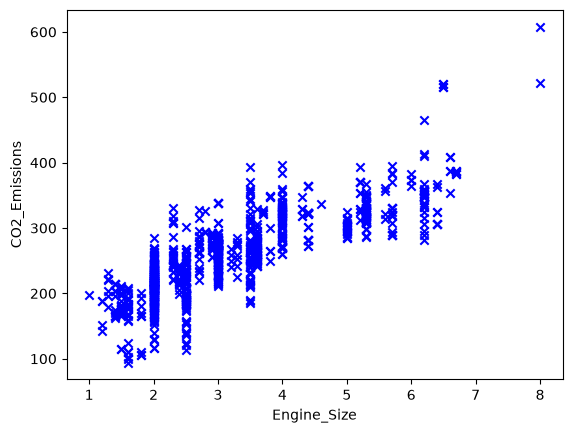

In [2]:
def build_plot(file_path, x, y):
    data = pd.read_csv(file_path)
    plt.scatter(data[x], data[y], c='blue', marker='x')
    plt.xlabel(x)
    plt.ylabel(y)
    return plt

build_plot('resources/CO2_emission.csv', 'Engine_Size', 'CO2_Emissions').show()

In [3]:
def extract_texts_from_file(file_path):
    """
    Extract the text data from the csv file

    Args:
        file_path (str): Relative location of the csv file in the project.

    Returns:
        pd.DataFrame: The data from the csv file.
    """
    return pd.read_csv(file_path)

data = extract_texts_from_file('resources/heart.csv')
print(data[:50])

    age  sex  cp  trtbps  chol  fbs  restecg  thalachh  exng  oldpeak  slp  \
0    63    1   3     145   233    1        0       150     0      2.3    0   
1    37    1   2     130   250    0        1       187     0      3.5    0   
2    41    0   1     130   204    0        0       172     0      1.4    2   
3    56    1   1     120   236    0        1       178     0      0.8    2   
4    57    0   0     120   354    0        1       163     1      0.6    2   
5    57    1   0     140   192    0        1       148     0      0.4    1   
6    56    0   1     140   294    0        0       153     0      1.3    1   
7    44    1   1     120   263    0        1       173     0      0.0    2   
8    52    1   2     172   199    1        1       162     0      0.5    2   
9    57    1   2     150   168    0        1       174     0      1.6    2   
10   54    1   0     140   239    0        1       160     0      1.2    2   
11   48    0   2     130   275    0        1       139     0    

`extract_texts_from_file` returns a `pandas.DataFrame` instead of a list of strings: every following task works with tabular numeric data, so a DataFrame keeps column names and types.

**Regression approach used below.** The data is first split into train (80%) and test (20%). The polynomial degree is selected by 5-fold cross-validation **on the train part only** using the one-standard-error rule: the simplest degree whose mean CV R² is within one standard error of the best one. The model is then fitted on train and evaluated once on test. The returned theta is `[intercept, coefficients...]` of the polynomial.

In [4]:
def polynomial_model(degree):
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), LinearRegression())


def select_polynomial_degree(X, y, degrees=range(1, 6), cv=None, groups=None):
    cv = cv or KFold(n_splits=5, shuffle=True, random_state=42)
    rows = {}
    for degree in degrees:
        fold_scores = cross_val_score(polynomial_model(degree), X, y, cv=cv, groups=groups, scoring="r2")
        rows[degree] = {"CV R2": fold_scores.mean(), "SE": fold_scores.std(ddof=1) / np.sqrt(len(fold_scores))}
    scores = pd.DataFrame(rows).T
    best = scores["CV R2"].idxmax()
    threshold = scores.loc[best, "CV R2"] - scores.loc[best, "SE"]
    chosen = int(scores.index[scores["CV R2"] >= threshold].min())
    return chosen, scores


def fit_polynomial(X_train, X_test, y_train, y_test, degree):
    model = polynomial_model(degree).fit(X_train, y_train)
    predictions = model.predict(X_test)
    print(f"degree={degree}  test R2={r2_score(y_test, predictions):.4f}  test MAE={mean_absolute_error(y_test, predictions):.3f}")
    regression = model[-1]
    theta = [float(regression.intercept_)] + [float(c) for c in regression.coef_]
    return model, theta


def plot_degree_scores(scores, chosen, title, file_name):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.errorbar(scores.index, scores["CV R2"], yerr=scores["SE"], marker="o", capsize=4)
    ax.scatter([chosen], [scores.loc[chosen, "CV R2"]], s=150, facecolors="none", edgecolors="tab:red", linewidths=2, label=f"chosen degree {chosen}")
    ax.set_xlabel("polynomial degree")
    ax.set_ylabel("5-fold CV R2 (train part)")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    fig.savefig(f"images/{file_name}", dpi=120)
    plt.show()


def regression_1d(data, x, y, name):
    X = data[[x]].to_numpy()
    target = data[y].to_numpy()
    X_train, X_test, y_train, y_test = train_test_split(X, target, test_size=0.2, random_state=42)
    degree, scores = select_polynomial_degree(X_train, y_train)
    print(scores.round(4).to_string())
    plot_degree_scores(scores, degree, f"{name}: model selection", f"{name}_degree_selection.png")
    model, theta = fit_polynomial(X_train, X_test, y_train, y_test, degree)

    grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(X_train, y_train, c="tab:blue", marker="x", alpha=0.5, label="train")
    ax.scatter(X_test, y_test, c="tab:orange", marker="x", alpha=0.7, label="test")
    ax.plot(grid, model.predict(grid), color="tab:red", linewidth=2, label=f"polynomial regression, degree {degree}")
    if degree != 1:
        linear = polynomial_model(1).fit(X_train, y_train)
        print(f"linear model for comparison: test R2={r2_score(y_test, linear.predict(X_test)):.4f}")
        ax.plot(grid, linear.predict(grid), color="gray", linestyle="--", linewidth=1.5, label="linear regression")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(name)
    ax.legend()
    fig.tight_layout()
    fig.savefig(f"images/{name}_model.png", dpi=120)
    plt.show()
    return theta

## CO2 emissions

Process file `CO2_emission.csv`. Build a model, that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

    CV R2      SE
1  0.6842  0.0105
2  0.6819  0.0062
3  0.6911  0.0083
4  0.6815  0.0172
5  0.5355  0.1595


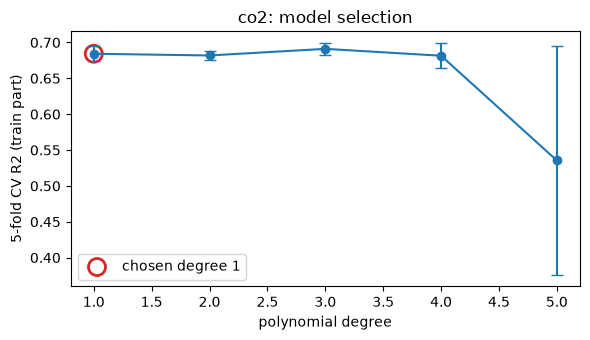

degree=1  test R2=0.6420  test MAE=28.571


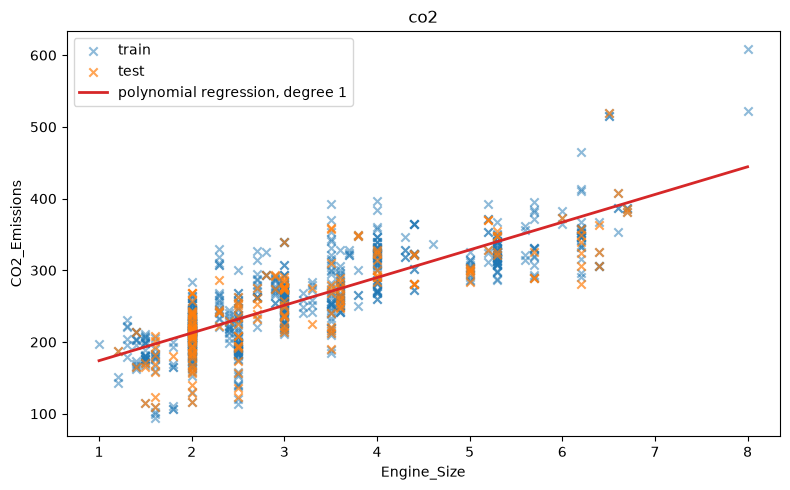

[135.41324486170805, 38.616765736036726]

In [5]:
def CO2_emissions(data):
    """
    Build a model that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

    Args:
        data: CO2 emissions data.

    Returns:
        list: The list of model theta parameters.
    """
    return regression_1d(data, "Engine_Size", "CO2_Emissions", "co2")

data = extract_texts_from_file('resources/CO2_emission.csv')
CO2_emissions(data)

**Results.** With the one-standard-error rule the linear model is chosen: polynomial degrees 2–4 improve the CV R² by less than one standard error (0.684 → 0.691), and degree 5 becomes unstable. Linear regression gives test R² = 0.64 and MAE ≈ 28.6 g/km. Engine size alone explains about two thirds of the variation in CO2 emissions; the rest depends on fuel type, vehicle class and transmission.

## Ice Cream Sales

Process file `ice_cream_selling_data.csv`. Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

    CV R2      SE
1 -0.1140  0.0672
2  0.9097  0.0284
3  0.8842  0.0345
4  0.9107  0.0241
5  0.9303  0.0232


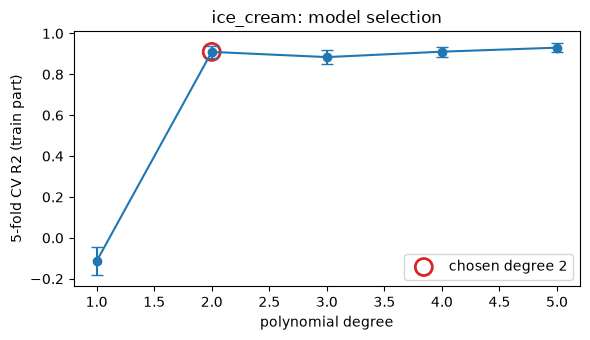

degree=2  test R2=0.8431  test MAE=3.230
linear model for comparison: test R2=-0.5751


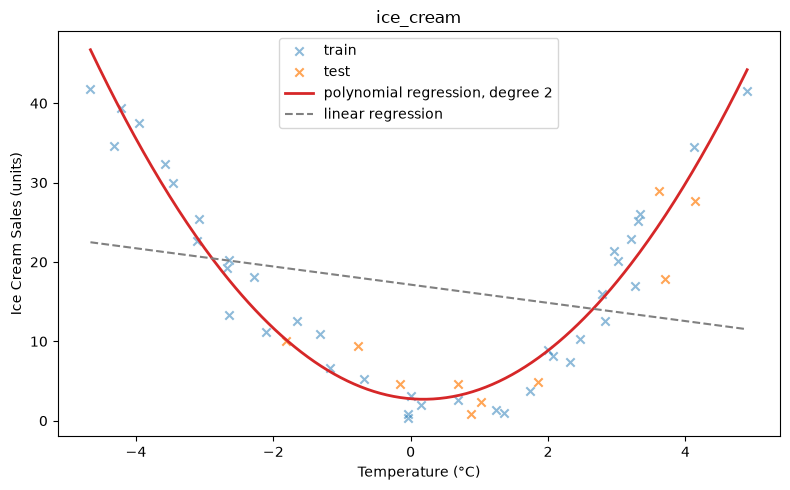

[2.768305829573862, -0.7064192581346763, 1.8714512493550586]

In [6]:
def ice_cream_selling(data):
    """
    Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

    Args:
        data: ice cream sales data.

    Returns:
        list: The list of model theta parameters.
    """
    return regression_1d(data, "Temperature (°C)", "Ice Cream Sales (units)", "ice_cream")

data = extract_texts_from_file('resources/ice_cream_selling_data.csv')
ice_cream_selling(data)

**Results.** The data is U-shaped: sales are high both at low and at high temperatures, so a straight line is useless (test R² = −0.58). A quadratic polynomial is the simplest model within one standard error of the best CV score; it gives test R² = 0.84 and MAE ≈ 3.2 units.

## Electric Power Consumption

Process file `powerconsumption.csv`. Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

    CV R2      SE
1  0.2395  0.0144
2  0.2796  0.0121
3  0.2875  0.0140
4  0.2896  0.0157


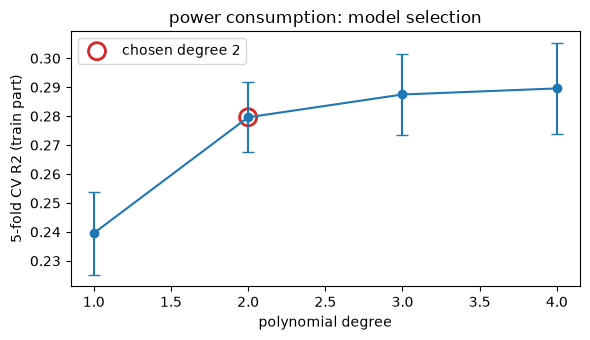

degree=2  test R2=0.2938  test MAE=11615.178
intercept                99114.109
Temperature              -3873.506
Humidity                   -18.017
WindSpeed               -13050.090
Temperature^2               82.919
Temperature Humidity        30.448
Temperature WindSpeed       74.684
Humidity^2                  -4.628
Humidity WindSpeed         -27.236
WindSpeed^2               2626.382


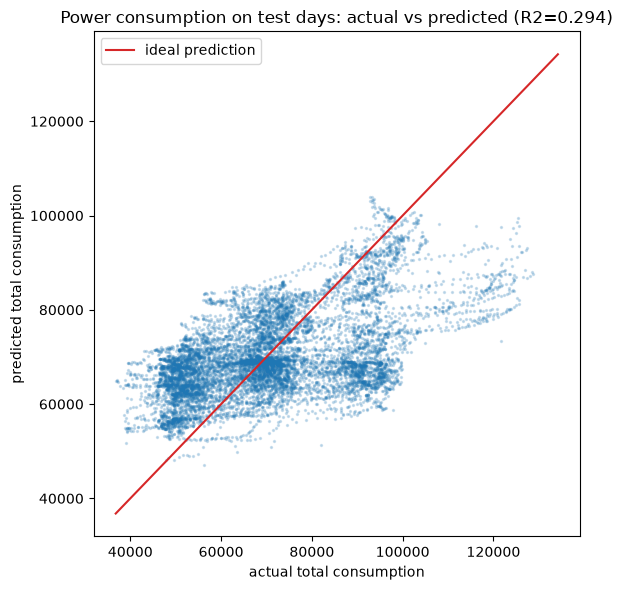

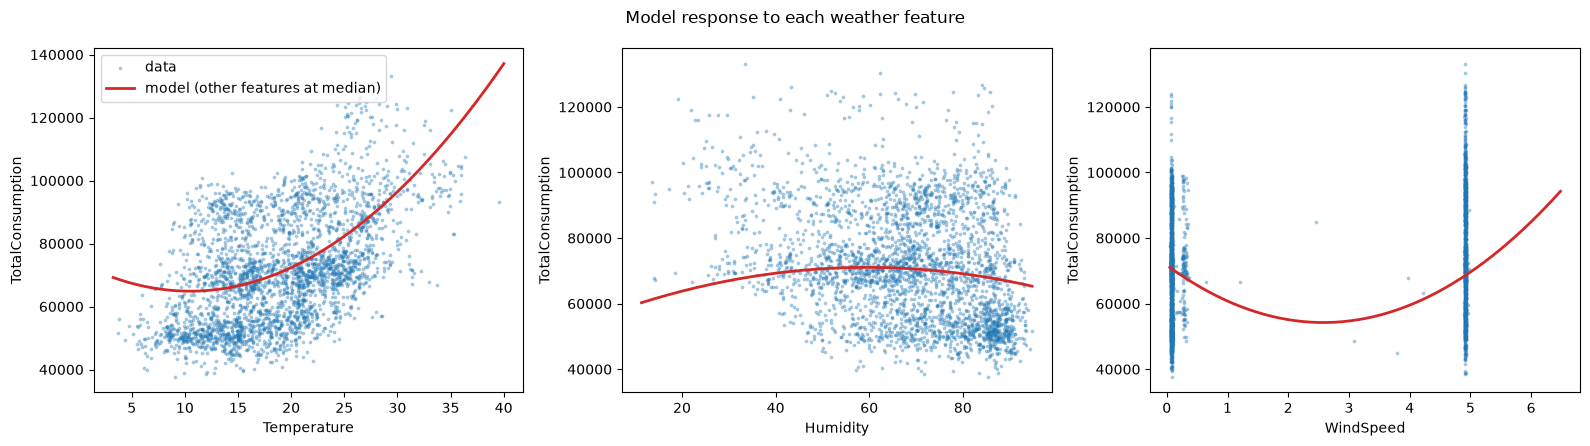

[99114.10876528123,
 -3873.5055171554723,
 -18.01656746587498,
 -13050.090281868188,
 82.9189982600729,
 30.448423611601754,
 74.68420347663157,
 -4.628329710544932,
 -27.23570942900618,
 2626.3816601295453]

In [7]:
WEATHER = ["Temperature", "Humidity", "WindSpeed"]


def power_consumption(data):
    """
    Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed.
    Visualize model on a plot.

    Args:
        data: power consumption data.

    Returns:
        list: The list of model theta parameters.
    """
    zones = [column for column in data.columns if column.startswith("PowerConsumption")]
    data = data.assign(TotalConsumption=data[zones].sum(axis=1))
    X = data[WEATHER].to_numpy()
    y = data["TotalConsumption"].to_numpy()
    days = pd.to_datetime(data["Datetime"], format="%m/%d/%Y %H:%M").dt.date.to_numpy()

    train_index, test_index = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(X, y, groups=days))
    X_train, X_test, y_train, y_test = X[train_index], X[test_index], y[train_index], y[test_index]
    degree, scores = select_polynomial_degree(X_train, y_train, degrees=range(1, 5), cv=GroupKFold(n_splits=5), groups=days[train_index])
    print(scores.round(4).to_string())
    plot_degree_scores(scores, degree, "power consumption: model selection", "power_degree_selection.png")
    model, theta = fit_polynomial(X_train, X_test, y_train, y_test, degree)
    print(pd.Series(theta, index=["intercept"] + list(model[0].get_feature_names_out(WEATHER))).round(3).to_string())

    predictions = model.predict(X_test)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(y_test, predictions, s=2, alpha=0.2)
    limits = [y.min(), y.max()]
    ax.plot(limits, limits, color="tab:red", label="ideal prediction")
    ax.set_xlabel("actual total consumption")
    ax.set_ylabel("predicted total consumption")
    ax.set_title(f"Power consumption on test days: actual vs predicted (R2={r2_score(y_test, predictions):.3f})")
    ax.legend()
    fig.tight_layout()
    fig.savefig("images/power_actual_vs_predicted.png", dpi=120)
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    medians = data[WEATHER].median()
    for ax, feature in zip(axes, WEATHER):
        grid = np.tile(medians.to_numpy(), (200, 1))
        grid[:, WEATHER.index(feature)] = np.linspace(data[feature].min(), data[feature].max(), 200)
        sample = data.sample(3000, random_state=42)
        ax.scatter(sample[feature], sample["TotalConsumption"], s=3, alpha=0.3, label="data")
        ax.plot(grid[:, WEATHER.index(feature)], model.predict(grid), color="tab:red", linewidth=2, label="model (other features at median)")
        ax.set_xlabel(feature)
        ax.set_ylabel("TotalConsumption")
    axes[0].legend()
    fig.suptitle("Model response to each weather feature")
    fig.tight_layout()
    fig.savefig("images/power_feature_effects.png", dpi=120)
    plt.show()
    return theta

data = extract_texts_from_file('resources/powerconsumption.csv')
power_consumption(data)

**Results.** The train/test split and the cross-validation are done by whole days (GroupShuffleSplit and GroupKFold); otherwise neighbouring 10-minute records of the same day would get into both train and test and inflate the score. Degree 2 is chosen (CV R² 0.28 versus 0.24 for the linear model), with test R² = 0.29. Weather explains only a small part of the consumption: most of it depends on the time of day and the day of the week, which are not among the allowed features. Consumption grows with temperature; humidity and wind speed have a weaker effect.

## Heart Conditions Predictions

Process file `heart.csv`. It has the following data:

- age - Age of the patient
- sex - Sex of the patient
- cp - Chest pain type ~ 0 = Typical Angina, 1 = Atypical Angina, 2 = Non-anginal Pain, 3 = Asymptomatic
- trtbps - Resting blood pressure (in mm Hg)
- chol - Cholestoral in mg/dl fetched via BMI sensor
- fbs - (fasting blood sugar > 120 mg/dl) ~ 1 = True, 0 = False
- restecg - Resting electrocardiographic results ~ 0 = Normal, 1 = ST-T wave normality, 2 = Left ventricular hypertrophy
- thalachh - Maximum heart rate achieved
- oldpeak - Previous peak
- slp - Slope
- caa - Number of major vessels
- thall - Thalium Stress Test result ~ (0,3)
- exng - Exercise induced angina ~ 1 = Yes, 0 = No
- output - Target variable - risk of heart attack - 1 is high chance of heart attack and 0 is low chance.

Use classification model (choose model best fitting model yourself). Choose parameters that would best fit for making a prediction on. Visualize model on a plot.

Do not forget to split data into train data and validation data. Validate your model.

removed duplicate rows: 1, rows left: 302


ridge classifier            0.8454
logistic regression         0.8277
logistic regression (L1)    0.8188
SGD classifier              0.7877

features kept by L1 regularization (17 of 22): ['sex', 'trtbps', 'chol', 'thalachh', 'exng', 'oldpeak', 'cp_1', 'cp_2', 'cp_3', 'restecg_1', 'slp_1', 'slp_2', 'caa_1', 'caa_2', 'caa_3', 'thall_2', 'thall_3']

best model: ridge classifier
validation accuracy=0.8026  f1=0.8276
              precision    recall  f1-score   support

    low risk       0.83      0.71      0.77        35
   high risk       0.78      0.88      0.83        41

    accuracy                           0.80        76
   macro avg       0.81      0.80      0.80        76
weighted avg       0.81      0.80      0.80        76



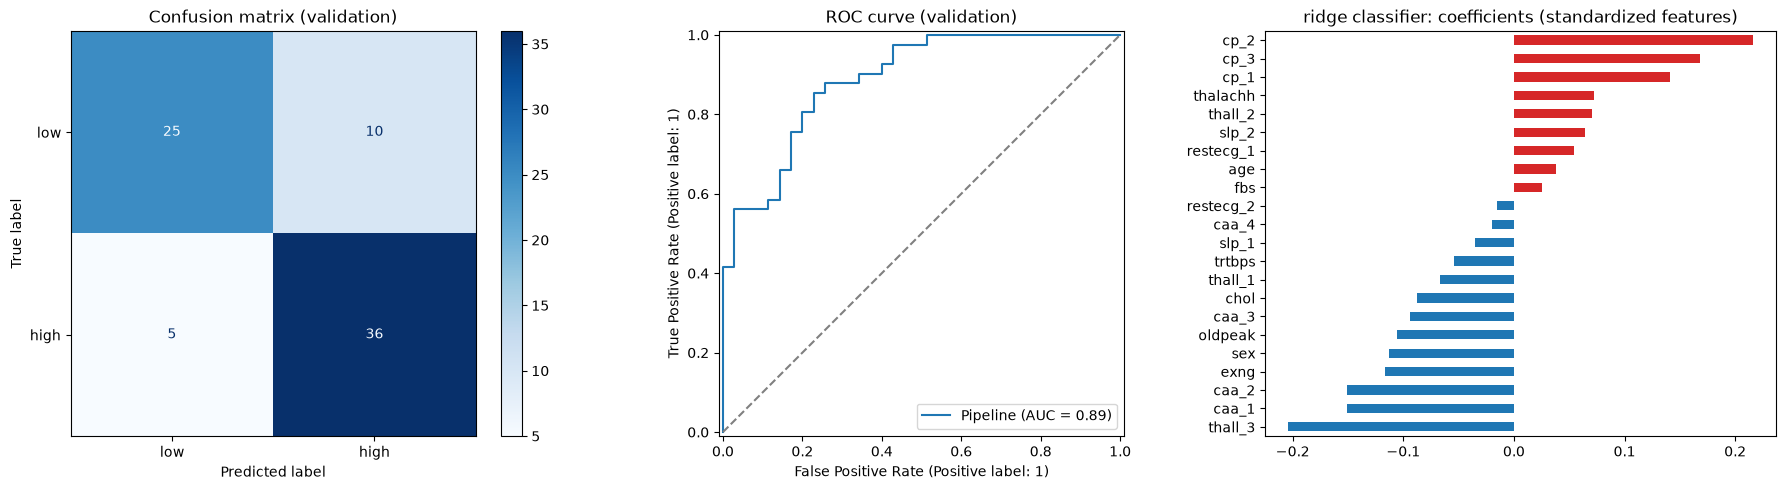

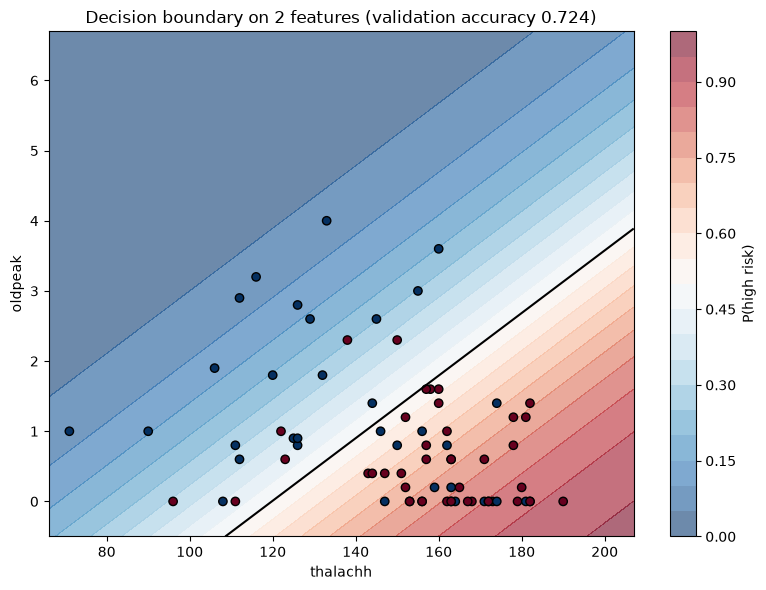

[0.08849557522123895,
 0.038016879380966866,
 -0.11310736672225329,
 -0.05374371354614122,
 -0.08727987414457981,
 0.025200063011315756,
 0.07255894925446055,
 -0.1164185879775418,
 -0.10596671484208722,
 0.1413955265983883,
 0.21612121495289235,
 0.1678546165614797,
 0.054185829592763024,
 -0.015545634037798874,
 -0.0350689288486277,
 0.06395154980560781,
 -0.1510492668780628,
 -0.15104509020282655,
 -0.09374367640719368,
 -0.020217310478934637,
 -0.06697698941630989,
 0.07027424103556713,
 -0.20388560244209453]

In [8]:
CATEGORICAL = ["cp", "restecg", "slp", "caa", "thall"]


def heart_features(data):
    return pd.get_dummies(data.drop(columns="output"), columns=CATEGORICAL, drop_first=True, dtype=float)


def heart_classification(data):
    """
    Build a model, that would classify risk category for heart attack.
    Visualize model on a plot.

    Args:
        data: heart medical data.

    Returns:
        list: The list of model theta parameters.
    """
    duplicates = int(data.duplicated().sum())
    data = data.drop_duplicates().reset_index(drop=True)
    print(f"removed duplicate rows: {duplicates}, rows left: {len(data)}")
    X = heart_features(data)
    y = data["output"]
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    candidates = {
        "logistic regression": LogisticRegression(max_iter=5000),
        "logistic regression (L1)": LogisticRegression(l1_ratio=1.0, solver="liblinear", C=0.5),
        "ridge classifier": RidgeClassifier(),
        "SGD classifier": SGDClassifier(loss="log_loss", random_state=42),
    }
    results = {}
    for name, estimator in candidates.items():
        model = make_pipeline(StandardScaler(), estimator)
        results[name] = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy").mean()
    results = pd.Series(results, name="5-fold CV accuracy").sort_values(ascending=False)
    print(results.round(4).to_string())

    selector = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1.0, solver="liblinear", C=0.5)).fit(X_train, y_train)
    selected = X.columns[np.abs(selector[-1].coef_[0]) > 1e-6]
    print(f"\nfeatures kept by L1 regularization ({len(selected)} of {X.shape[1]}): {list(selected)}")

    best_name = results.index[0]
    model = make_pipeline(StandardScaler(), candidates[best_name]).fit(X_train, y_train)
    predictions = model.predict(X_val)
    print(f"\nbest model: {best_name}")
    print(f"validation accuracy={accuracy_score(y_val, predictions):.4f}  f1={f1_score(y_val, predictions):.4f}")
    print(classification_report(y_val, predictions, target_names=["low risk", "high risk"]))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    ConfusionMatrixDisplay.from_predictions(y_val, predictions, display_labels=["low", "high"], cmap="Blues", ax=axes[0])
    axes[0].set_title("Confusion matrix (validation)")
    RocCurveDisplay.from_estimator(model, X_val, y_val, ax=axes[1])
    axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
    axes[1].set_title("ROC curve (validation)")
    coefficients = pd.Series(np.ravel(model[-1].coef_), index=X.columns).sort_values()
    coefficients.plot.barh(ax=axes[2], color=np.where(coefficients > 0, "tab:red", "tab:blue"))
    axes[2].set_title(f"{best_name}: coefficients (standardized features)")
    fig.tight_layout()
    fig.savefig("images/heart_classification.png", dpi=120)
    plt.show()

    two = ["thalachh", "oldpeak"]
    plane = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train[two], y_train)
    xx, yy = np.meshgrid(
        np.linspace(X[two[0]].min() - 5, X[two[0]].max() + 5, 300),
        np.linspace(X[two[1]].min() - 0.5, X[two[1]].max() + 0.5, 300),
    )
    probability = plane.predict_proba(pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=two))[:, 1].reshape(xx.shape)
    fig, ax = plt.subplots(figsize=(8, 6))
    contour = ax.contourf(xx, yy, probability, levels=20, cmap="RdBu_r", alpha=0.6)
    ax.contour(xx, yy, probability, levels=[0.5], colors="black")
    ax.scatter(X_val[two[0]], X_val[two[1]], c=y_val, cmap="RdBu_r", edgecolor="black")
    fig.colorbar(contour, ax=ax, label="P(high risk)")
    ax.set_xlabel(two[0])
    ax.set_ylabel(two[1])
    ax.set_title(f"Decision boundary on 2 features (validation accuracy {plane.score(X_val[two], y_val):.3f})")
    fig.tight_layout()
    fig.savefig("images/heart_decision_boundary.png", dpi=120)
    plt.show()

    return [float(c) for c in np.ravel(model[-1].intercept_)] + [float(c) for c in np.ravel(model[-1].coef_)]

data = extract_texts_from_file('resources/heart.csv')
heart_classification(data)

**Results.** One duplicated row was removed. Four linear classifiers were compared with 5-fold CV on the train part (75%), and the ridge classifier was the best (CV accuracy 0.845). On the validation part (25%) it reaches accuracy 0.80, F1 0.83 and recall 0.88 for the high-risk class, so most high-risk patients are detected. L1-regularized logistic regression keeps 17 of 22 features and drops age, fasting blood sugar and some rare categories, so they add little information. The strongest predictors are chest pain type, the thalium test result, the number of major vessels, exercise-induced angina and oldpeak.

## Additional (extra credit)

There are more files in the resources folder. Take a look at the. Visualize data in these files. Choose ML algorithm for building a model and making predictions for new data. Visualize the model.

beta_1=716.357  beta_2=0.997201
test R2=0.9788
 Year  predicted GDP
 2015   9.462174e+12
 2016   9.712780e+12
 2017   9.896436e+12
 2018   1.002932e+13
 2019   1.012457e+13


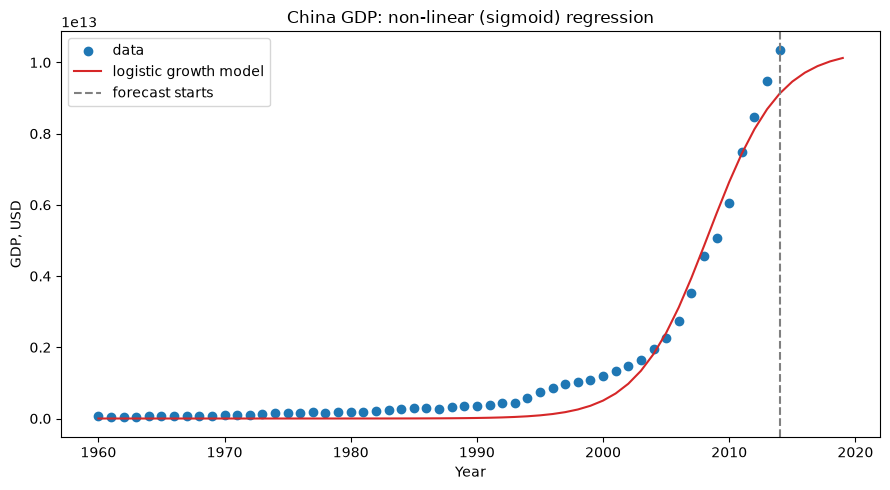

[716.3571364362698, 0.997200836594405]

In [9]:
from scipy.optimize import curve_fit


def logistic_growth(x, beta_1, beta_2):
    return 1 / (1 + np.exp(-beta_1 * (x - beta_2)))


def additional(data):
    x = data["Year"].to_numpy(dtype=float)
    y = data["Value"].to_numpy(dtype=float)
    x_scaled = x / x.max()
    y_scaled = y / y.max()

    x_train, x_test, y_train, y_test = train_test_split(x_scaled, y_scaled, test_size=0.2, random_state=42)
    theta, _ = curve_fit(logistic_growth, x_train, y_train, p0=[500, 0.998], maxfev=20000)
    print(f"beta_1={theta[0]:.3f}  beta_2={theta[1]:.6f}")
    print(f"test R2={r2_score(y_test, logistic_growth(x_test, *theta)):.4f}")

    future = np.arange(x.min(), x.max() + 6)
    prediction = logistic_growth(future / x.max(), *theta) * y.max()
    print(pd.DataFrame({"Year": future[-5:].astype(int), "predicted GDP": prediction[-5:]}).to_string(index=False))

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.scatter(x, y, label="data")
    ax.plot(future, prediction, color="tab:red", label="logistic growth model")
    ax.axvline(x.max(), color="gray", linestyle="--", label="forecast starts")
    ax.set_xlabel("Year")
    ax.set_ylabel("GDP, USD")
    ax.set_title("China GDP: non-linear (sigmoid) regression")
    ax.legend()
    fig.tight_layout()
    fig.savefig("images/china_gdp_model.png", dpi=120)
    plt.show()
    return [float(t) for t in theta]

data = extract_texts_from_file('resources/china_gdp.csv')
additional(data)

**Results.** The logistic (sigmoid) curve fits the historical data well (test R² = 0.98). Limitation: a sigmoid assumes that growth slows down and saturates, so the forecast flattens at about 1.0e13 USD, while the real GDP of China kept growing (about 1.4e13 USD in 2019). The model describes the observed range well, but it is not suitable for long-term extrapolation.

1    0.7286
2    0.8429
3    0.8786
4    1.0000
5    1.0000
6    1.0000
7    1.0000
max_depth=4  test accuracy=0.9833
              precision    recall  f1-score   support

       drugA       0.88      1.00      0.93         7
       drugB       1.00      0.80      0.89         5
       drugC       1.00      1.00      1.00         5
       drugX       1.00      1.00      1.00        16
       drugY       1.00      1.00      1.00        27

    accuracy                           0.98        60
   macro avg       0.97      0.96      0.96        60
weighted avg       0.99      0.98      0.98        60



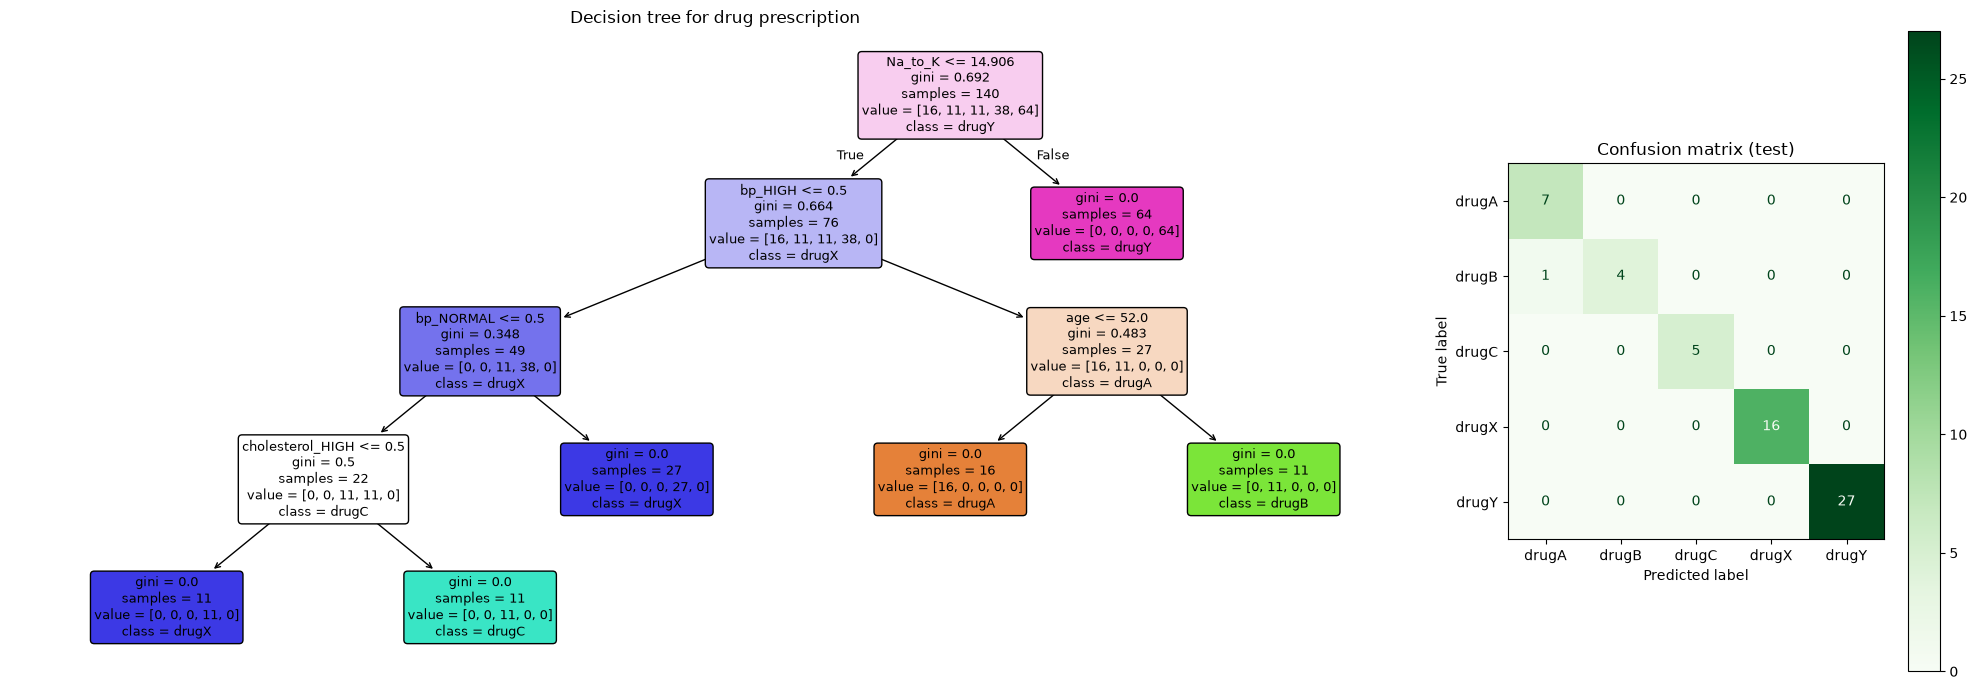

 age sex   bp cholesterol  Na_to_K predicted_drug
  30   F HIGH      NORMAL     12.0          drugA
  65   M  LOW        HIGH      9.5          drugC


In [10]:
from sklearn.tree import DecisionTreeClassifier, plot_tree


def additional_drug(data):
    X = pd.get_dummies(data.drop(columns="drug"), columns=["sex", "bp", "cholesterol"], dtype=float)
    y = data["drug"]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

    depths = {depth: cross_val_score(DecisionTreeClassifier(max_depth=depth, random_state=42), X_train, y_train, cv=5).mean() for depth in range(1, 8)}
    depth = max(depths, key=depths.get)
    print(pd.Series(depths, name="CV accuracy").round(4).to_string())
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train, y_train)
    predictions = tree.predict(X_test)
    print(f"max_depth={depth}  test accuracy={accuracy_score(y_test, predictions):.4f}")
    print(classification_report(y_test, predictions))

    fig, axes = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={"width_ratios": [3, 1]})
    plot_tree(tree, feature_names=X.columns, class_names=tree.classes_, filled=True, rounded=True, ax=axes[0], fontsize=9)
    axes[0].set_title("Decision tree for drug prescription")
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap="Greens", ax=axes[1])
    axes[1].set_title("Confusion matrix (test)")
    fig.tight_layout()
    fig.savefig("images/drug_decision_tree.png", dpi=120)
    plt.show()

    new_patients = pd.DataFrame(
        [{"age": 30, "sex": "F", "bp": "HIGH", "cholesterol": "NORMAL", "Na_to_K": 12.0},
         {"age": 65, "sex": "M", "bp": "LOW", "cholesterol": "HIGH", "Na_to_K": 9.5}]
    )
    new_X = pd.get_dummies(new_patients, columns=["sex", "bp", "cholesterol"], dtype=float).reindex(columns=X.columns, fill_value=0)
    print(new_patients.assign(predicted_drug=tree.predict(new_X)).to_string(index=False))

additional_drug(extract_texts_from_file('resources/drug.csv'))

**Results.** Cross-validation selects max_depth = 4, the smallest depth with CV accuracy 1.0. The tree reaches 98% accuracy on the test set; the first split is on Na_to_K, followed by blood pressure, age and cholesterol. The model is then used to predict the drug for new patients.

## Machine learning analysis on texts

Predict text score (sentiment, holistic score, etc., any other target label) using machine learning algorithm you see best fit for the task. Choose kaggle dataset from available below. Display classification report (confusion matrix, accuracy, f1 score, etc.).

- Learning Agency Lab - Automated Essay Scoring 2.0: predict holistic text score given full_text (student essays) https://www.kaggle.com/competitions/learning-agency-lab-automated-essay-scoring-2
- 100K Coursera's Course Reviews Dataset: predict the final rating (1 to 5) based on the text of the review https://www.kaggle.com/datasets/septa97/100k-courseras-course-reviews-dataset
- LLM - Detect AI Generated Text: predict the target label (0 being written by student and 1 being written by LLM) given the full text https://www.kaggle.com/competitions/llm-detect-ai-generated-text
- 42K+ Udemy Course Enrollment Information Dataset🔥: classify course categories using Title and Summary; compare text-only features against combined title-and-summary features https://www.kaggle.com/datasets/songseungwon/2020-udemy-courses-dataset
- TMDB 5000 Movie Dataset: movie classification based on description https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata?select=tmdb_5000_movies.csv

Label
1     2469
2     2251
3     5071
4    18054
5    79173

train=68491  validation=17123  test=21404



model selection on the validation set:
                                     accuracy  macro f1  weighted f1  MAE (stars)
model                                                                            
linear SVM (balanced)                  0.7625    0.4541       0.7542       0.2971
logistic regression                    0.7803    0.4534       0.7545       0.2807
logistic regression (balanced)         0.7157    0.4508       0.7297       0.3448
ridge regression (ordinal, rounded)    0.7183    0.3826       0.7224       0.3200



best model by validation macro f1: linear SVM (balanced), refitted on train+validation and evaluated once on the test set
accuracy       0.7678
macro f1       0.4631
weighted f1    0.7596
MAE (stars)    0.2883
              precision    recall  f1-score   support

           1      0.463     0.498     0.480       494
           2      0.238     0.233     0.235       450
           3      0.296     0.327     0.311      1014
           4      0.453     0.348     0.394      3611
           5      0.876     0.915     0.895     15835

    accuracy                          0.768     21404
   macro avg      0.465     0.464     0.463     21404
weighted avg      0.755     0.768     0.760     21404



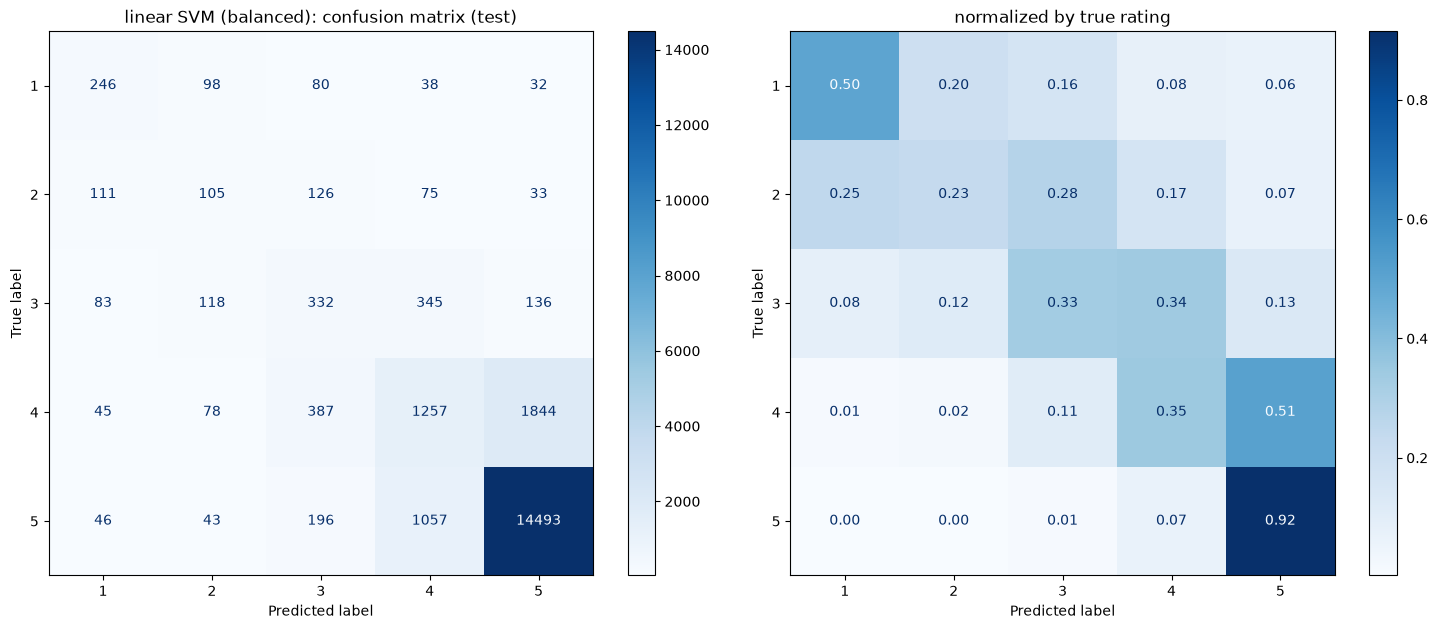

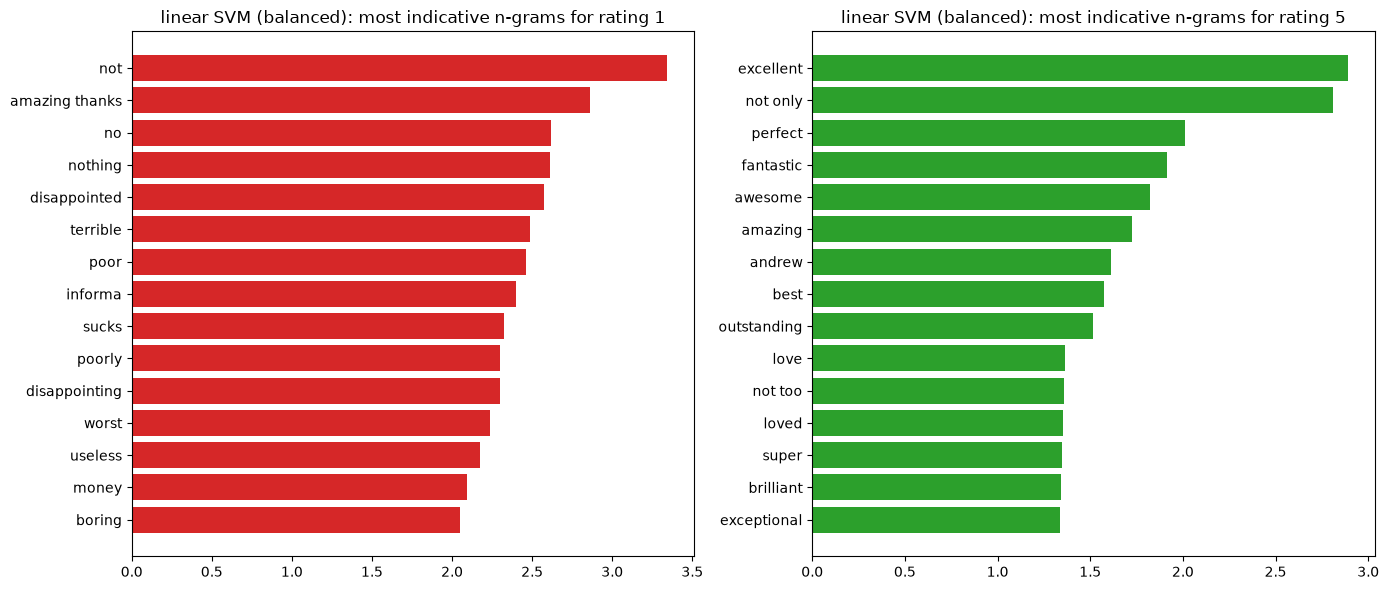

                                                     review  predicted rating
The best course I have ever taken, very clear explanations!                 5
          Boring lectures and the assignments were useless.                 1
              It was ok, some parts are good but too basic.                 4


In [11]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.svm import LinearSVC


class RoundedRidge(Ridge):
    def predict(self, X):
        return np.clip(np.rint(super().predict(X)), 1, 5).astype(int)


def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle using kagglehub.

    Args:
        url (str): The URL of the Kaggle dataset.
        csv_file (str): The name of the CSV file to load from the dataset.
    Returns:
        pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """
    df = kagglehub.dataset_load(
            KaggleDatasetAdapter.PANDAS,
            url,
            csv_file
        )
    return df

def classify_text_ml(df):
    """
    Classify text data using a machine learning model.

    Args:
        df (pd.DataFrame): The input DataFrame containing text data.

    Returns:
        None
    """
    df = df.dropna(subset=["Review"])
    print(df["Label"].value_counts().sort_index().to_string())
    X_rest, X_test, y_rest, y_test = train_test_split(df["Review"], df["Label"], test_size=0.2, stratify=df["Label"], random_state=42)
    X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.2, stratify=y_rest, random_state=42)
    print(f"\ntrain={len(X_train)}  validation={len(X_val)}  test={len(X_test)}")

    def make_vectorizer():
        return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=3, max_features=200000, sublinear_tf=True)

    candidates = {
        "logistic regression": lambda: LogisticRegression(max_iter=2000, C=4),
        "logistic regression (balanced)": lambda: LogisticRegression(max_iter=2000, C=4, class_weight="balanced"),
        "linear SVM (balanced)": lambda: LinearSVC(C=0.5, class_weight="balanced"),
        "ridge regression (ordinal, rounded)": lambda: RoundedRidge(alpha=1.0),
    }

    def scores(y_true, predictions):
        return {
            "accuracy": accuracy_score(y_true, predictions),
            "macro f1": f1_score(y_true, predictions, average="macro"),
            "weighted f1": f1_score(y_true, predictions, average="weighted"),
            "MAE (stars)": mean_absolute_error(y_true, predictions),
        }

    vectorizer = make_vectorizer()
    train_vectors = vectorizer.fit_transform(X_train)
    val_vectors = vectorizer.transform(X_val)
    rows = []
    for name, factory in candidates.items():
        model = factory().fit(train_vectors, y_train)
        rows.append({"model": name, **scores(y_val, model.predict(val_vectors))})
    summary = pd.DataFrame(rows).set_index("model").sort_values("macro f1", ascending=False)
    print("\nmodel selection on the validation set:")
    print(summary.round(4).to_string())

    best = summary.index[0]
    vectorizer = make_vectorizer()
    rest_vectors = vectorizer.fit_transform(X_rest)
    test_vectors = vectorizer.transform(X_test)
    model = candidates[best]().fit(rest_vectors, y_rest)
    predictions = model.predict(test_vectors)
    print(f"\nbest model by validation macro f1: {best}, refitted on train+validation and evaluated once on the test set")
    print(pd.Series(scores(y_test, predictions)).round(4).to_string())
    print(classification_report(y_test, predictions, digits=3))

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap="Blues", ax=axes[0], values_format="d")
    axes[0].set_title(f"{best}: confusion matrix (test)")
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, normalize="true", cmap="Blues", ax=axes[1], values_format=".2f")
    axes[1].set_title("normalized by true rating")
    fig.tight_layout()
    fig.savefig("images/coursera_confusion_matrix.png", dpi=120)
    plt.show()

    if hasattr(model, "classes_") and np.ndim(model.coef_) == 2:
        terms = np.array(vectorizer.get_feature_names_out())
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        for ax, label, color in zip(axes, [1, 5], ["tab:red", "tab:green"]):
            weights = model.coef_[list(model.classes_).index(label)]
            top = np.argsort(weights)[-15:]
            ax.barh(terms[top], weights[top], color=color)
            ax.set_title(f"{best}: most indicative n-grams for rating {label}")
        fig.tight_layout()
        fig.savefig("images/coursera_top_ngrams.png", dpi=120)
        plt.show()

    examples = ["The best course I have ever taken, very clear explanations!", "Boring lectures and the assignments were useless.", "It was ok, some parts are good but too basic."]
    print(pd.DataFrame({"review": examples, "predicted rating": model.predict(vectorizer.transform(examples))}).to_string(index=False))

df = load_dataset('septa97/100k-courseras-course-reviews-dataset', 'reviews.csv')
classify_text_ml(df)

**Results.** The ratings are very imbalanced (74% of reviews have 5 stars). The model is selected on a separate validation set, then refitted on train+validation and evaluated once on the test set. Linear SVM with balanced class weights has the best macro F1 (0.45 on validation; 0.46 on test with accuracy 0.77 and MAE 0.29 stars). Extreme ratings are recognized well (5 stars: F1 0.90, 1 star: F1 0.48), while ratings 2, 3 and 4 are often confused with their neighbours, because the difference between them in the text is subtle. Treating the rating as an ordinal value (ridge regression rounded to 1–5) gives a lower macro F1 (0.38), so classification is preferred.